# P1: Predicción de Demanda de Viajes (Regresión) - MiBici

**Objetivo:** Desarrollar un modelo baseline y su respectivo pipeline para predecir el número de viajes que se iniciarán en una estación o zona en un periodo futuro (por hora). 

**Justificación:** Esta información es clave para los operadores del sistema con el fin de planear la distribución de la flota y anticipar desabastecimientos.

#### Importamos las librerías y rutas

In [1266]:
import sys
import mlflow
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlflow.models import infer_signature
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


### 1. Carga de Datos Procesados
Cargamos el conjunto de datos que ya pasó por el proceso de limpieza y unificación de estaciones (fase de ingeniería de datos). Verificamos las dimensiones y la integridad básica antes de modelar.

In [1267]:
# Resolver la raíz del repositorio sin rutas absolutas
ROOT_DIR = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Importar rutas procesadas desde el config del proyecto
from proyecto_mibici.config import TRIPS_PROCESSED_PATH, STATIONS_PROCESSED_PATH

# Carga de datos columnar de alta velocidad desde los Parquet
df_trips = pd.read_parquet(TRIPS_PROCESSED_PATH)
df_stations = pd.read_parquet(STATIONS_PROCESSED_PATH)

print(f"Viajes cargados: {len(df_trips):,}")
print(f"Estaciones registradas: {len(df_stations):,}")

Viajes cargados: 7,894,097
Estaciones registradas: 484


### 2. Análisis Exploratorio de Datos (EDA Inicial)
Evaluamos la estructura general del dataset de viajes de MiBici: dimensiones, tipos de datos, presencia de valores nulos o duplicados, y el rango temporal que abarca el estudio para garantizar la integridad de la fuente.

In [1268]:
# 1. Dimensiones y vista previa de los datos
print(f"Dimensiones del dataset crudo de viajes: Filas: {df_trips.shape[0]:,} | Columnas: {df_trips.shape[1]:,}")
display(df_trips.head(3))

# 2. Tipos de datos y memoria utilizada
print("\nInformación General y Tipos de Datos")
df_trips.info()

# 3. Análisis de valores faltantes (porcentaje y conteo)
missing = pd.DataFrame({
    "missing_count": df_trips.isna().sum(),
    "missing_%": df_trips.isna().mean() * 100
})
print("\nPorcentaje de Valores Nulos")
display(missing[missing["missing_count"] > 0].sort_values("missing_%", ascending=False))

# 4. Duplicados e Identificadores únicos
print(f"\nFilas duplicadas exactas: {df_trips.duplicated().sum():,}")
print(f"IDs de viaje duplicados (viaje_id): {df_trips['viaje_id'].duplicated().sum():,}")

# 5. Rango temporal del sistema
print(f"\nRango Temporal")
print(f"Inicio del periodo: {df_trips['inicio_del_viaje'].min()}")
print(f"Fin del periodo:    {df_trips['inicio_del_viaje'].max()}")

Dimensiones del dataset crudo de viajes: Filas: 7,894,097 | Columnas: 8


,viaje_id,usuario_id,genero,ano_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,37162342,601273,M,1982.0,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395
1,37162343,1571524,M,2003.0,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260
2,37162344,1435200,F,1984.0,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260



Información General y Tipos de Datos
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7894097 entries, 0 to 7894096
Data columns (total 8 columns):
 #   Column             Dtype         
---  ------             -----         
 0   viaje_id           int64         
 1   usuario_id         int64         
 2   genero             object        
 3   ano_de_nacimiento  float64       
 4   inicio_del_viaje   datetime64[ns]
 5   fin_del_viaje      datetime64[ns]
 6   origen_id          int32         
 7   destino_id         int32         
dtypes: datetime64[ns](2), float64(1), int32(2), int64(2), object(1)
memory usage: 421.6+ MB

Porcentaje de Valores Nulos


,missing_count,missing_%
genero,62743,0.794809
ano_de_nacimiento,1436,0.018191



Filas duplicadas exactas: 758
IDs de viaje duplicados (viaje_id): 758

Rango Temporal
Inicio del periodo: 2025-01-01 00:00:44
Fin del periodo:    2026-09-30 23:59:48


- El dataset cuenta con 7,894,097 registros distribuidos en 8 columnas. Los tipos de datos son coherentes.
- La columna genero presenta un porcentaje mínimo de nulos (0.79% / 62,743 registros).
- La variable año_de_nacimiento tiene una afectación prácticamente imperceptible (0.01% / 1,436 registros). Dado que estos nulos son mínimos en comparación con el total de millones de filas, no representan un riesgo analítico para el modelado agregado por hora.
- Se detectaron 758 filas duplicadas y el mismo número de viaje_id repetidos, lo que confirma que son copias idénticas a nivel de registro y pueden limpiarse de forma segura mediante un `drop_duplicates(subset=['viaje_id'])`.
- El estudio comprende un periodo sólido de casi 21 meses, abarcando desde el **1 de enero de 2025** hasta el **30 de septiembre de 2026**, otorgando una estacionalidad amplia para capturar patrones de movilidad urbana tanto entre semana como en fines de semana.

In [1269]:
# 1. Dimensiones del catálogo de estaciones
print(f"Dimensiones de estaciones - Filas: {df_stations.shape[0]:,} | Columnas: {df_stations.shape[1]:,}")

# 2. Vista previa de las primeras filas
display(df_stations.head(3))

# 3. Tipos de datos y uso de memoria
print("\nInformación General del Catálogo")
df_stations.info()

# 4. Análisis de valores faltantes (filtrando solo los que tienen nulos)
missing_stations = pd.DataFrame({
    "missing_count": df_stations.isna().sum(),
    "missing_%": df_stations.isna().mean() * 100
})

print("\nValores Faltantes en Estaciones")
missing_con_nulos = missing_stations[missing_stations["missing_count"] > 0]
if not missing_con_nulos.empty:
    display(missing_con_nulos.sort_values("missing_%", ascending=False))
else:
    print("No se encontraron valores nulos en el catálogo de estaciones.")

# 5. Revisar filas duplicadas exactas
print(f"\nFilas duplicadas exactas en estaciones: {df_stations.duplicated().sum():,}")


Dimensiones de estaciones - Filas: 484 | Columnas: 8


,id,name,latitude,longitude,dpcapacity,station_code,municipality_code,address
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15,GDL-001,GDL,C. Epigmenio Glez. / Av. 16 de Sept.
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15,GDL-002,GDL,C. Colonias / Av. Niños héroes
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19,GDL-003,GDL,C. Vidrio / Av. Chapultepec



Información General del Catálogo
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 484 non-null    int32  
 1   name               484 non-null    object 
 2   latitude           484 non-null    float64
 3   longitude          484 non-null    float64
 4   dpcapacity         484 non-null    int32  
 5   station_code       484 non-null    object 
 6   municipality_code  484 non-null    object 
 7   address            484 non-null    object 
dtypes: float64(2), int32(2), object(4)
memory usage: 26.6+ KB

Valores Faltantes en Estaciones
No se encontraron valores nulos en el catálogo de estaciones.

Filas duplicadas exactas en estaciones: 0


- El catálogo cuenta con un total de 484 estaciones y 8 columnas descriptivas que incluyen geolocalización (latitude, longitude), capacidad de anclaje (dpcapacity), códigos de estación y dirección postal.
- No se encontraron valores nulos en ninguna de las 484 filas, ni tampoco registros duplicados exactos. Esto demuestra que el catálogo de infraestructura se encuentra limpio y consistente para realizar cruces espaciales seguros con la base de datos de viajes.

#### 2.1. Limpieza de Duplicados, Validación de Estaciones y Anomalías Temporales

In [1270]:
# Identificar todos los registros cuyos viaje_id aparecen más de una vez
duplicados_id = df_trips[
    df_trips.duplicated(subset="viaje_id", keep=False)
].sort_values("viaje_id")

print("Filas involucradas en IDs repetidos:", len(duplicados_id))
print("IDs distintos repetidos:", duplicados_id["viaje_id"].nunique())

# Verificar si cada ID repetido tiene una sola versión de sus datos
columnas_viaje = df_trips.columns.tolist()

variantes_por_id = (
    duplicados_id.groupby("viaje_id")[columnas_viaje]
    .nunique()
)

ids_con_conflictos = variantes_por_id[
    variantes_por_id.gt(1).any(axis=1)
]

print("IDs con registros contradictorios:", len(ids_con_conflictos))

# Mostrar ejemplos para inspección
display(duplicados_id.head(10))

if not ids_con_conflictos.empty:
    display(
        duplicados_id[
            duplicados_id["viaje_id"].isin(ids_con_conflictos.index)
        ].sort_values("viaje_id").head(20)
    )


Filas involucradas en IDs repetidos: 1516
IDs distintos repetidos: 758
IDs con registros contradictorios: 0


,viaje_id,usuario_id,genero,ano_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
7404173,45705948,4610130,M,2001.0,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303
7404174,45705948,4610130,M,2001.0,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303
7404995,45706846,4610130,M,2001.0,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265
7404996,45706846,4610130,M,2001.0,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265
7405403,45707318,1110472,F,1992.0,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105
7405404,45707318,1110472,F,1992.0,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105
7405423,45707337,4610243,M,1972.0,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445
7405424,45707337,4610243,M,1972.0,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445
7405744,45707670,1163105,F,1987.0,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217
7405745,45707670,1163105,F,1987.0,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217


- Se detectaron 1,516 filas repetidas en total, las cuales corresponden a 758 identificadores únicos (viaje_id) duplicados.
- Al evaluar la consistencia de los datos entre filas repetidas, se comprobó que no existen discrepancias en los tiempos, estaciones o perfiles de usuario. Como se observa en la muestra, las filas duplicadas son copias exactas del registro.
- Al tratarse de duplicados exactos sin conflicto de información, se confirma que es seguro y metodológicamente correcto aplicar un `drop_duplicates(subset=['viaje_id'])` para limpiar la base de datos sin alterar la integridad de los eventos de viaje.

In [1271]:
# Crear una copia de trabajo y eliminar duplicados exactos
df_trips_clean = df_trips.drop_duplicates().copy()

# Validar la unicidad de viaje_id
assert df_trips_clean["viaje_id"].is_unique, (
    "Hay viaje_id repetidos que requieren investigación."
)

print(f"Filas originales: {len(df_trips):,}")
print(f"Filas después de limpiar: {len(df_trips_clean):,}")
print(f"Filas eliminadas: {len(df_trips) - len(df_trips_clean):,}")
print(f"IDs de viaje únicos: {df_trips_clean['viaje_id'].nunique():,}")


Filas originales: 7,894,097
Filas después de limpiar: 7,893,339
Filas eliminadas: 758
IDs de viaje únicos: 7,893,339


In [1272]:
# Normalizar el catálogo de estaciones para las validaciones
station_ids = set(df_stations["id"])

origin_ids = set(df_trips_clean["origen_id"].unique())
destination_ids = set(df_trips_clean["destino_id"].unique())

# Identificadores de estaciones que no existen en el catálogo
missing_origins = origin_ids - station_ids
missing_destinations = destination_ids - station_ids

print(f"Estaciones únicas como origen: {len(origin_ids):,}")
print(f"Estaciones únicas como destino: {len(destination_ids):,}")
print(f"Orígenes ausentes del catálogo: {len(missing_origins):,}")
print(f"Destinos ausentes del catálogo: {len(missing_destinations):,}")

# Revisar valores temporales anómalos
duracion = (
    df_trips_clean["fin_del_viaje"]
    - df_trips_clean["inicio_del_viaje"]
)

print(f"\nViajes con duración negativa: {(duracion < pd.Timedelta(0)).sum():,}")
print(f"Viajes con duración cero: {(duracion == pd.Timedelta(0)).sum():,}")
print(f"Viajes con fecha final ausente: {df_trips_clean['fin_del_viaje'].isna().sum():,}")


Estaciones únicas como origen: 472
Estaciones únicas como destino: 472
Orígenes ausentes del catálogo: 2
Destinos ausentes del catálogo: 2

Viajes con duración negativa: 0
Viajes con duración cero: 5,814
Viajes con fecha final ausente: 0


- Se eliminaron con éxito las 758 filas duplicadas, reduciendo el dataset de 7,894,097 a 7,893,339 registros limpios, garantizando una correspondencia uno a uno para el viaje_id.
- De las 484 estaciones del catálogo, se identificaron 472 estaciones activas tanto en orígenes como en destinos. Se detectaron 2 estaciones ausentes en el catálogo oficial (correspondientes a los IDs anómalos 405 y 407 que analizaremos posteriormente).
> * **Anomalías Temporales (Duración de los Viajes):**
>   * *Duraciones negativas:* **0 casos**, lo que indica que las marcas temporales (`inicio_del_viaje` vs `fin_del_viaje`) están cronológicamente ordenadas.
>   * *Fechas finales ausentes:* **0 casos**, asegurando que no hay registros incompletos por este factor.
>   * *Viajes con duración cero:* Se registraron **5,814 trayectos** con una duración de cero segundos. En sistemas de micromovilidad, esto suele representar incidentes donde el usuario desbloquea la bicicleta, percibe una falla mecánica inmediata o decide no realizar el viaje y la devuelve en el mismo anclaje de forma instantánea.

#### 2.2 Diagnóstico de Cobertura Temporal y Estacional
Analizamos la actividad histórica por estación (origen_id) para identificar discrepancias con el catálogo oficial y calcular el porcentaje de horas sin viajes. Esto nos permite detectar estaciones inactivas o con intermitencias operativas antes de construir la malla horaria continua.

In [1273]:
# Usar los viajes sin duplicados
df_base = df_trips_clean.copy()

# Estaciones presentes en los viajes que no están en el catálogo
station_ids = set(df_stations["id"])
origin_ids = set(df_base["origen_id"].unique())

print("IDs de origen ausentes del catálogo:",
      sorted(origin_ids - station_ids))

# Diagnóstico de cobertura por estación
df_base["hour_window"] = (
    df_base["inicio_del_viaje"].dt.floor("h")
)

coverage = (
    df_base.groupby("origen_id")
    .agg(
        first_hour=("hour_window", "min"),
        last_hour=("hour_window", "max"),
        observed_hours=("hour_window", "nunique"),
        total_trips=("viaje_id", "size"),
    )
)

coverage["expected_hours"] = (
    (coverage["last_hour"] - coverage["first_hour"])
    / pd.Timedelta(hours=1)
).astype(int) + 1

coverage["hours_without_trips"] = (
    coverage["expected_hours"] - coverage["observed_hours"]
)

coverage["pct_hours_without_trips"] = (
    coverage["hours_without_trips"]
    / coverage["expected_hours"] * 100
)

display(
    coverage.sort_values(
        "pct_hours_without_trips", ascending=False
    ).head(15)
)

print(
    "Total de horas que se completarían con cero:",
    f"{coverage['hours_without_trips'].sum():,}"
)


IDs de origen ausentes del catálogo: [np.int32(405), np.int32(407)]


/var/folders/wf/zp59pk9n53g840vgbj1n2ghh0000gn/T/ipykernel_55243/287481251.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  / pd.Timedelta(hours=1)


,first_hour,last_hour,observed_hours,total_trips,expected_hours,hours_without_trips,pct_hours_without_trips
origen_id,,,,,,,
180,2025-01-01 07:00:00,2026-09-30 20:00:00,617,1676,15302,14685,95.967847
465,2026-06-26 22:00:00,2026-09-28 22:00:00,123,142,2257,2134,94.550288
511,2026-08-03 18:00:00,2026-09-30 17:00:00,98,120,1392,1294,92.959770
437,2026-06-04 07:00:00,2026-09-30 20:00:00,267,311,2846,2579,90.618412
510,2026-07-31 13:00:00,2026-09-30 08:00:00,139,191,1460,1321,90.479452
509,2026-07-29 21:00:00,2026-09-30 17:00:00,152,179,1509,1357,89.927104
468,2026-06-22 19:00:00,2026-09-30 16:00:00,251,309,2398,2147,89.532944
500,2026-06-19 17:00:00,2026-09-30 07:00:00,261,337,2463,2202,89.403167
497,2026-07-02 19:00:00,2026-09-30 20:00:00,234,321,2162,1928,89.176688


Total de horas que se completarían con cero: 3,164,883


Analizamos la actividad horaria histórica de cada estación (origen_id) para evaluar su nivel de operación y determinar cuántas horas carecen de viajes registrados dentro de su ventana de actividad.
- Se detectaron explícitamente los IDs de origen 405 y 407, los cuales aparecen en los registros de viajes pero no se encuentran en la infraestructura del catálogo oficial.
- La tabla muestra las estaciones con mayor porcentaje de horas sin viajes (pct_hours_without_trips). Por ejemplo, la estación 180 presenta un 95.96% de horas vacías (14,685 horas sin viajes de un total esperado de 15,302), y la estación 465 un 94.55%. Estas cifras pueden reflejar estaciones periféricas o con aperturas tardías/intermitencias severas.
- El diagnóstico acumuló un total de 3,164,883 horas sin viajes en todo el sistema, las cuales deberán ser tratadas (completadas con ceros) al construir la malla horaria continua para asegurar que el modelo de regresión aprenda correctamente tanto los periodos de alta demanda como los de inactividad.

#### 2.3 Filtrado de Estaciones Inactivas o Fantasma
Establecemos un umbral máximo de horas sin viajes (`MAX_PCT_VACIAS = 90`) para descartar estaciones que pasaron inactivas la mayor parte del periodo. Asimismo, cruzamos el resultado con el catálogo oficial para remover IDs erróneos o ausentes (como las estaciones 405 y 407).

In [1274]:
# Estaciones con demasiadas horas vacías = probablemente inactivas
MAX_PCT_VACIAS = 90

estaciones_validas = coverage[
    coverage["pct_hours_without_trips"] <= MAX_PCT_VACIAS
].index

# Quitamos las que no están en el catálogo (405 y 407)
estaciones_validas = estaciones_validas.intersection(df_stations["id"])

df_trips_filtrado = df_trips_clean[
    df_trips_clean["origen_id"].isin(estaciones_validas)
]

print(f"Estaciones antes: {df_trips_clean['origen_id'].nunique()}")
print(f"Estaciones después: {len(estaciones_validas)}")

Estaciones antes: 472
Estaciones después: 465


El filtro de estaciones inactivas se calculó con todo el periodo, incluido el de prueba; en un despliegue real debería calcularse solo con datos pasados.

In [1275]:
descartadas = coverage[
    coverage["pct_hours_without_trips"] > MAX_PCT_VACIAS
].sort_values("first_hour")

print(descartadas[["first_hour", "total_trips", "pct_hours_without_trips"]].head(15))

                   first_hour  total_trips  pct_hours_without_trips
origen_id                                                          
180       2025-01-01 07:00:00         1676                95.967847
437       2026-06-04 07:00:00          311                90.618412
465       2026-06-26 22:00:00          142                94.550288
510       2026-07-31 13:00:00          191                90.479452
511       2026-08-03 18:00:00          120                92.959770


Se excluyen 7 de las 472 estaciones: 2 ausentes del catálogo (405 y 407) y 5 con más de 90% de horas sin viajes (180, 437, 465, 510 y 511). Las estaciones de baja demanda pero operativas se conservan, porque sus ceros son información real.

#### 2.4 Análisis Visual de la Serie Temporal (Evolución Diaria)
Graficamos el volumen total de viajes agregados por día para inspeccionar visualmente la macro-tendencia del sistema, detectar posibles anomalías o interrupciones prolongadas en el servicio y confirmar el comportamiento estacional de la demanda.

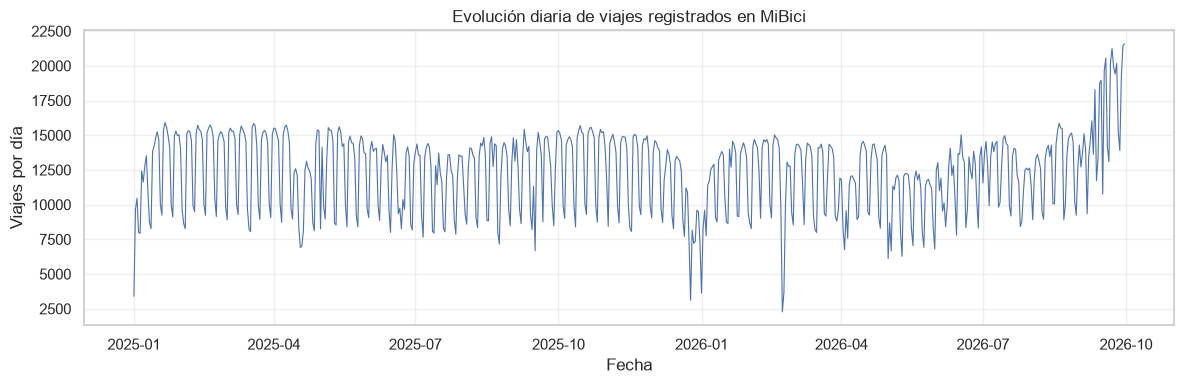

In [1276]:
df_daily = (
    df_trips_filtrado 
    .assign(fecha=lambda x: x["inicio_del_viaje"].dt.floor("D"))
    .groupby("fecha")
    .size()
    .rename("total_viajes")
)

plt.figure(figsize=(12, 4))
plt.plot(df_daily.index, df_daily.values, linewidth=0.8)

plt.title("Evolución diaria de viajes registrados en MiBici")
plt.xlabel("Fecha")
plt.ylabel("Viajes por día")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- La gráfica muestra una alta frecuencia oscilatoria regular a lo largo de todo el periodo (2025-2026), reflejando los ciclos semanales donde los picos altos corresponden a días laborables y las caídas pronunciadas representan los fines de semana.
- Se aprecian caídas estacionales marcadas en momentos específicos del año, como a finales de diciembre/principios de enero (periodo decembrino) y durante los primeros meses de 2026, donde el volumen diario desciende notablemente, lo cual es compatible con una reducción de la movilidad urbana.
- Hacia mediados de 2026 (meses de julio a septiembre), se observa un incremento significativo en el volumen total de viajes diarios, superando los 20,000 viajes, lo cual indica un crecimiento en la adopción o uso del sistema de MiBici en el cierre de la serie temporal.

### 3. Ingeniería de Características y Construcción de la Malla Horaria
Agrupamos los viajes por ventanas de una hora (hour_window) y por estación de origen (origen_id). Posteriormente, generamos variables de rezago (lags) para que el modelo aprenda del comportamiento histórico inmediato de cada estación sin caer en data leakage.

Para transformar los eventos discretos de los viajes en un formato apto para algoritmos de regresión, ejecutamos el siguiente pipeline:
1. **Agregación horaria:** Agrupamos los viajes por estación y ventana de una hora (`hour_window`).
2. **Malla temporal continua:** Creamos un rango de tiempo continuo entre el primer y último viaje de cada estación, rellenando con ceros (`0`) las horas sin registros. Esto asume una demanda nula real en esos periodos.
3. **Variables de Retraso (*Lags*):** Generamos características históricas para capturar la inercia temporal sin caer en fuga de datos (*data leakage*):
   * `lag_1h`: Proyección inmediata (1 hora antes de la hora objetivo).
   * `lag_24h`: Patrón diario (ayer a la misma hora).
   * `lag_168h`: Patrón semanal (la semana pasada a la misma hora).
4. **Variables Cíclicas de Calendario:** Codificamos la hora del día mediante transformaciones trigonométricas (seno y coseno) para reflejar su naturaleza continua (donde las 23:00 horas están cerca de las 00:00 horas).

In [1277]:
def build_hourly_demand_with_lags(df_trips):
    """Construye la malla horaria por estación, rellena ceros y calcula
    rezagos, medias móviles y el objetivo (demanda de la hora siguiente).

    Cada fila representa la hora t; el objetivo es la demanda de t+1.
    """

    # 1. Asignar cada viaje a su ventana horaria (14:34 -> 14:00)
    df = df_trips.assign(
        hour_window=pd.to_datetime(df_trips["inicio_del_viaje"]).dt.floor("h")
    )

    # 2. Contar viajes por estación y hora
    df_demand = (
        df.groupby(["origen_id", "hour_window"])
        .size()
        .rename("demand_count")
        .reset_index()
    )

    # 3. Malla continua: todas las horas entre el primer y el último viaje
    #    de cada estación, para no perder las horas sin viajes
    df_bounds = df_demand.groupby("origen_id")["hour_window"].agg(["min", "max"])
    grid = pd.concat([
        pd.DataFrame({
            "origen_id": sid,
            "hour_window": pd.date_range(r["min"], r["max"], freq="h"),
        })
        for sid, r in df_bounds.iterrows()
    ])

    # 4. Rellenar con 0 las horas sin viajes (se asume demanda nula)
    df_out = grid.merge(df_demand, on=["origen_id", "hour_window"], how="left")
    df_out["demand_count"] = df_out["demand_count"].fillna(0).astype(int)
    df_out = df_out.sort_values(["origen_id", "hour_window"]).reset_index(drop=True)

    # 5. Rezagos, medidos respecto a la hora objetivo t+1.
    #    Por eso se usa shift(23) y shift(167) desde la fila t:
    #    t-23 = (t+1)-24 h  y  t-167 = (t+1)-168 h.
    por_estacion = df_out.groupby("origen_id")["demand_count"]
    df_out["lag_1h"] = df_out["demand_count"]      # hora t, 1 h antes del objetivo
    df_out["lag_24h"] = por_estacion.shift(23)     # misma hora de ayer
    df_out["lag_168h"] = por_estacion.shift(167)   # misma hora de la semana pasada

    # 6. Medias móviles: solo usan horas <= t, no hay fuga de información.
    #    min_periods evita NaN al inicio de la serie de cada estación.
    df_out["rolling_3h"] = (
        por_estacion.rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
    )
    df_out["rolling_168h"] = (
        por_estacion.rolling(168, min_periods=24).mean().reset_index(level=0, drop=True)
    )

    # 7. Objetivo: demanda de la hora siguiente (t+1)
    df_out["target_next_hour"] = por_estacion.shift(-1)

    # 8. El objetivo solo es válido si la fila siguiente es exactamente
    #    una hora después dentro de la misma estación (sin huecos en la malla)
    next_hour = df_out.groupby("origen_id")["hour_window"].shift(-1)
    valid_next_hour = next_hour == df_out["hour_window"] + pd.Timedelta(hours=1)
    df_out.loc[~valid_next_hour, "target_next_hour"] = np.nan

    # 9. Descartar filas sin historial suficiente o sin objetivo válido
    required_columns = ["lag_1h", "lag_24h", "lag_168h", "target_next_hour"]
    return df_out.dropna(subset=required_columns).reset_index(drop=True)

In [1278]:
def add_calendar_features(df):
    """Agrega variables de calendario para la hora objetivo."""
    df = df.copy()

    # La demanda objetivo corresponde a la siguiente hora
    df["target_hour"] = df["hour_window"] + pd.Timedelta(hours=1)

    # Calendario de la hora que se quiere predecir
    df["target_hour_of_day"] = df["target_hour"].dt.hour
    df["target_dayofweek"] = df["target_hour"].dt.dayofweek

    df["target_is_weekend"] = (
        df["target_dayofweek"].isin([5, 6]).astype(int)
    )

    # Representación cíclica de la hora objetivo
    df["target_hour_sin"] = np.sin(
        2 * np.pi * df["target_hour_of_day"] / 24
    )
    df["target_hour_cos"] = np.cos(
        2 * np.pi * df["target_hour_of_day"] / 24
    )

    return df

Se incorporaron dos medias móviles por estación, calculadas solo con horas ya observadas: una de 3 horas, que resume la actividad inmediata, y una de 168 horas, que cubre un ciclo semanal completo y aproxima el nivel normal de demanda de cada estación sin sesgarse por la hora o el día. Las ventanas se eligieron a priori y no se optimizaron; explorar otras longitudes queda como trabajo futuro.

Los rezagos se miden respecto a la hora objetivo t+1: lag_1h es la demanda de la hora t (1 hora antes del objetivo), lag_24h la de t+1−24 h y lag_168h la de t+1−168 h. Por eso se calculan con shift(23) y shift(167) desde la fila t.

In [1279]:
df_p1 = build_hourly_demand_with_lags(df_trips_filtrado)
df_p1 = add_calendar_features(df_p1)

display(
    df_p1[
        [
            "origen_id",
            "hour_window",
            "demand_count",
            "lag_1h",
            "lag_24h",
            "lag_168h",
            "target_next_hour",
        ]
    ].head(10)
)


/var/folders/wf/zp59pk9n53g840vgbj1n2ghh0000gn/T/ipykernel_55243/2365845484.py:60: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  valid_next_hour = next_hour == df_out["hour_window"] + pd.Timedelta(hours=1)
/var/folders/wf/zp59pk9n53g840vgbj1n2ghh0000gn/T/ipykernel_55243/2618135808.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  df["target_hour"] = df["hour_window"] + pd.Timedelta(hours=1)


,origen_id,hour_window,demand_count,lag_1h,lag_24h,lag_168h,target_next_hour
0,2,2025-01-08 07:00:00,3,3,10.0,1.0,6.0
1,2,2025-01-08 08:00:00,6,6,6.0,1.0,12.0
2,2,2025-01-08 09:00:00,12,12,1.0,1.0,5.0
3,2,2025-01-08 10:00:00,5,5,1.0,0.0,6.0
4,2,2025-01-08 11:00:00,6,6,2.0,0.0,0.0
5,2,2025-01-08 12:00:00,0,0,5.0,0.0,2.0
6,2,2025-01-08 13:00:00,2,2,2.0,0.0,6.0
7,2,2025-01-08 14:00:00,6,6,3.0,0.0,7.0
8,2,2025-01-08 15:00:00,7,7,6.0,1.0,2.0
9,2,2025-01-08 16:00:00,2,2,3.0,0.0,2.0


In [1280]:
print("Dimensiones de df_p1:", df_p1.shape)
print("Estaciones:", df_p1["origen_id"].nunique())
print("Periodo:", df_p1["hour_window"].min(),
      "a", df_p1["hour_window"].max())

display(
    df_p1.isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)

Dimensiones de df_p1: (5759504, 15)
Estaciones: 465
Periodo: 2025-01-07 23:00:00 a 2026-09-30 22:00:00


,missing_values
origen_id,0
hour_window,0
demand_count,0
lag_1h,0
lag_24h,0
lag_168h,0
rolling_3h,0
rolling_168h,0
target_next_hour,0
target_hour,0


In [1281]:
# Estaciones con viajes de origen en los datos limpios
n_stations_raw = df_trips_clean["origen_id"].nunique()

# Estaciones que sobreviven al filtro de lags y objetivo
n_stations_model = df_p1["origen_id"].nunique()

print("Estaciones en datos originales:", n_stations_raw)
print("Estaciones en dataset de modelado:", n_stations_model)

# Comparar los viajes originales con la demanda de la malla
print("Viajes originales:", len(df_trips_clean))
print("Demanda acumulada en df_p1:", df_p1["demand_count"].sum())
print("Suma del objetivo:", df_p1["target_next_hour"].sum())

Estaciones en datos originales: 472
Estaciones en dataset de modelado: 465
Viajes originales: 7893339
Demanda acumulada en df_p1: 7818485
Suma del objetivo: 7818771.0


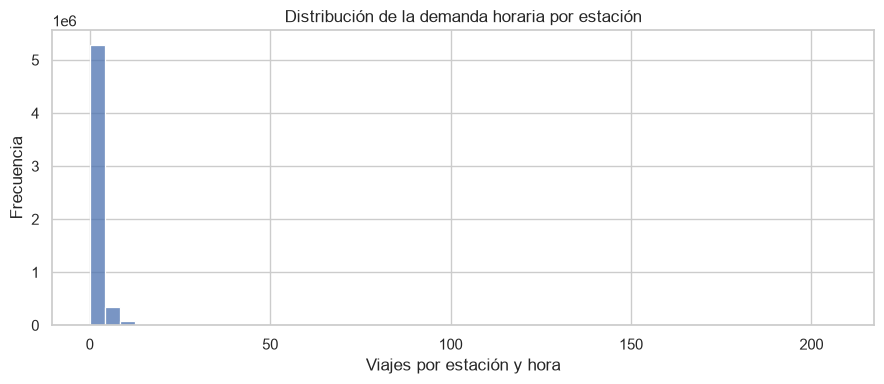

Porcentaje de observaciones con demanda cero: 53.71 %


In [1282]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df_p1,
    x="demand_count",
    bins=50
)

plt.title("Distribución de la demanda horaria por estación")
plt.xlabel("Viajes por estación y hora")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

print(
    "Porcentaje de observaciones con demanda cero:",
    round(df_p1["demand_count"].eq(0).mean() * 100, 2),
    "%"
)

- El dataset procesado para el modelado cuenta con 5,759,504 registros y 15 variables descriptivas. La ventana temporal consolidada abarca desde el 7 de enero de 2025 a las 23:00 hrs hasta el 30 de septiembre de 2026 a las 22:00 hrs**, permitiendo el cálculo correcto de los rezagos de una semana (`lag_168h`).
- La validación de valores faltantes confirma un dataset completamente limpio (0 nulos en todas las columnas, incluyendo variables predictoras, objetivos y características de calendario), lo cual garantiza que el pipeline de eliminación de registros incompletos operó correctamente.
- De las 472 estaciones iniciales con actividad, un total de 465 estaciones sobrevivieron al proceso de construcción de lags y ventanas temporales continuas.
- El total de viajes originales limpios era de 7,893,339, de los cuales 7,818,485 fueron perfectamente mapeados dentro de la malla horaria continua. La diferencia se debe a las 7 estaciones excluidas, a las primeras 167 horas de cada estación (calentamiento de lags) y a la última hora sin objetivo.
- El histograma y la naturaleza de los datos reflejan un claro sesgo hacia la inactividad horaria, donde una gran proporción de las observaciones concentran cero viajes por estación y hora (demand_count = 0), lo cual es característico de los sistemas de bicicletas compartidas en horarios nocturnos o en estaciones de menor afluencia.


### 4. Exploratorio Específico del Conjunto de Entrenamiento (Año 2025)
Para comprender los patrones de comportamiento antes de entrenar los modelos predictivos, analizamos en detalle el subconjunto correspondiente al año 2025 (3,151,882 registros en la malla horaria, abarcando 370 estaciones con observaciones y un total de 4,465,694 viajes procesados).

In [1283]:
# Subconjunto de 2025 (periodo de entrenamiento)
df_p1_2025 = df_p1.loc[
    df_p1["hour_window"].dt.year == 2025
].copy()

# Resumen de los datos para EDA
total_viajes_procesados = df_p1_2025["demand_count"].sum()
total_estaciones = df_p1_2025["origen_id"].nunique()
fecha_min = df_p1_2025["hour_window"].min().strftime("%Y-%m-%d %H:%M")
fecha_max = df_p1_2025["hour_window"].max().strftime("%Y-%m-%d %H:%M")

print("RESUMEN GENERAL DEL DATASET PARA 2025(MIBICI)")
print(f"Total de estaciones únicas analizadas: {total_estaciones}")
print(f"Total de viajes procesados en la malla: {total_viajes_procesados:,}")
print(f"Rango temporal de la serie: {fecha_min} a {fecha_max}")
print(
    f"Filas totales en la matriz de modelado (Malla horaria): {len(df_p1_2025):,}"
)

RESUMEN GENERAL DEL DATASET PARA 2025(MIBICI)
Total de estaciones únicas analizadas: 370
Total de viajes procesados en la malla: 4,465,694
Rango temporal de la serie: 2025-01-07 23:00 a 2025-12-31 23:00
Filas totales en la matriz de modelado (Malla horaria): 3,151,882


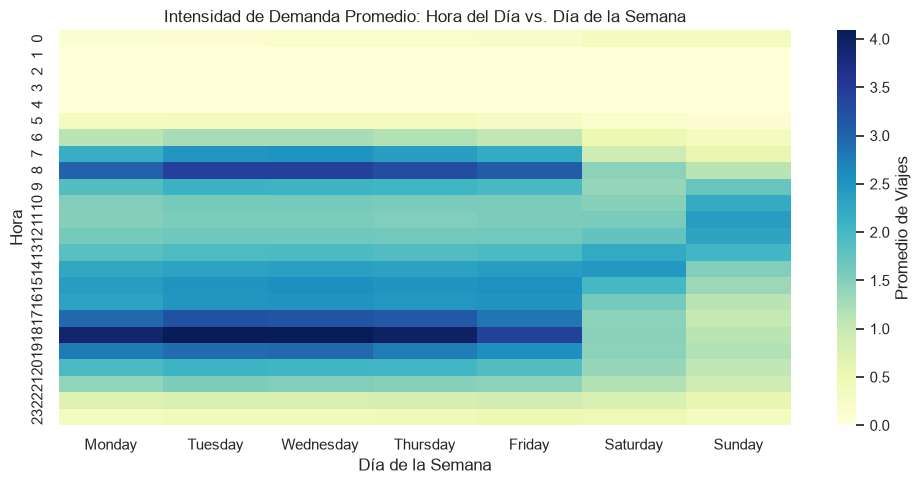

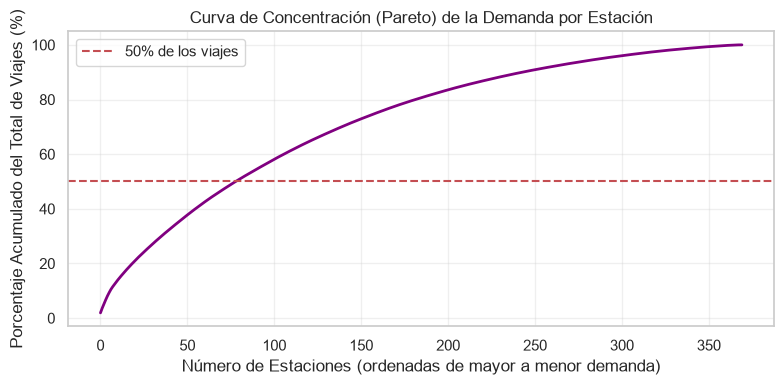

Estaciones para alcanzar 50% de la demanda: 79


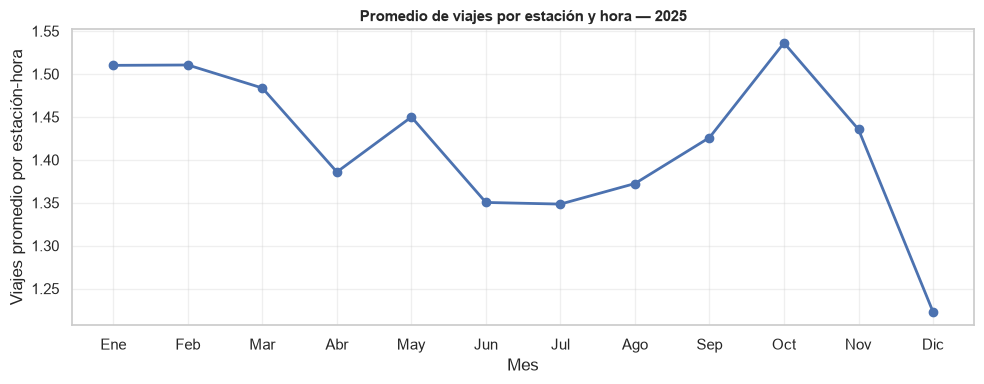

In [1284]:
# Mapa de calor (Hora del día vs Día de la semana)
plt.figure(figsize=(10, 5))
df_p1_2025['hour'] = df_p1_2025['hour_window'].dt.hour
df_p1_2025['day_of_week'] = df_p1_2025['hour_window'].dt.day_name()

heatmap_data = df_p1_2025.pivot_table(
    index='hour', columns='day_of_week', values='demand_count', aggfunc='mean'
)
# Ordenar días de la semana correctamente
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
heatmap_data = heatmap_data.reindex(columns=days_order)

sns.heatmap(heatmap_data, cmap='YlGnBu', cbar_kws={'label': 'Promedio de Viajes'})
plt.title(
    'Intensidad de Demanda Promedio: Hora del Día vs. Día de la Semana'
)
plt.xlabel('Día de la Semana')
plt.ylabel('Hora')
plt.tight_layout()
plt.show()

# Curva de Concentración (Pareto) de las Estaciones
# Cuantifica exactamente qué porcentaje del total de viajes concentran las top estaciones.
station_totals = (
    df_p1_2025.groupby('origen_id')['demand_count']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
station_totals['cumulative_percentage'] = (
    station_totals['demand_count'].cumsum()
    / station_totals['demand_count'].sum()
) * 100

plt.figure(figsize=(8, 4))
plt.plot(station_totals.index, station_totals['cumulative_percentage'], color='purple', linewidth=2)
plt.axhline(y=50, color='r', linestyle='--', label='50% de los viajes')
plt.title('Curva de Concentración (Pareto) de la Demanda por Estación')
plt.xlabel('Número de Estaciones (ordenadas de mayor a menor demanda)')
plt.ylabel('Porcentaje Acumulado del Total de Viajes (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

station_totals = (
    df_p1_2025.groupby("origen_id")["demand_count"]
    .sum()
    .sort_values(ascending=False)
)

cumulative_share = (
    station_totals.cumsum() / station_totals.sum()
)

stations_for_50pct = (
    cumulative_share.searchsorted(0.50) + 1
)

print(
    f"Estaciones para alcanzar 50% de la demanda: "
    f"{stations_for_50pct}"
)

# Evolución Mensual Normalizada (Promedio de Viajes por Hora y Estación)
df_p1_2025["month"] = df_p1_2025["hour_window"].dt.month

# Calcular el promedio de demanda por hora/estación activa por mes
# Promedio de demanda por estación y hora para cada mes de 2025
monthly_trend = (
    df_p1_2025
    .assign(month=df_p1_2025["hour_window"].dt.month)
    .groupby("month")["demand_count"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

plt.figure(figsize=(10, 4))
plt.plot(
    month_names,
    monthly_trend.values,
    marker="o",
    linewidth=2,
    markersize=6,
)

plt.title(
    "Promedio de viajes por estación y hora — 2025",
    fontsize=11,
    fontweight="bold",
)
plt.xlabel("Mes")
plt.ylabel("Viajes promedio por estación-hora")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Top 5 estaciones con mayor demanda acumulada
df_p1_2025["origen_id"] = df_p1_2025["origen_id"].astype(int)
df_stations["id"] = df_stations["id"].astype(int)

# Agrupar la demanda total por estación en tu dataset procesado
top_5_stations = (
    df_p1_2025.groupby("origen_id")["demand_count"]
    .sum()
    .reset_index()
    .sort_values(by="demand_count", ascending=False)
    .head(5)
)

df_stations[["id", "name"]]

# Unir con el catálogo de estaciones de manera segura
top_5_stations = top_5_stations.merge(
#    df_stations[["id", col_nombre]], left_on="origen_id", right_on="id", how="left"
    df_stations[["id", "name"]], left_on="origen_id", right_on="id", how="left"
)

# Calcular el porcentaje que representan del total de la red
total_red_viajes = df_p1_2025["demand_count"].sum()
top_5_stations["porcentaje_red"] = (
    top_5_stations["demand_count"] / total_red_viajes
) * 100

# Seleccionar y renombrar columnas finales para presentación
top_5_stations = top_5_stations[
    ["origen_id", "name", "demand_count", "porcentaje_red"]
]
top_5_stations.columns = [
    "ID",
    "Nombre de Estación",
    "Total de Viajes",
    "% del Total de la Red",
]
top_5_stations["% del Total de la Red"] = top_5_stations[
    "% del Total de la Red"
].round(2)

# Mostrar tabla formateada en el notebook
print("TOP 5 DE ESTACIONES CLAVE EN LA RED")
display(top_5_stations.reset_index(drop=True))

TOP 5 DE ESTACIONES CLAVE EN LA RED


,ID,Nombre de Estación,Total de Viajes,% del Total de la Red
0,51,(GDL-049) Lopez Cotilla / Penitenciaría,85521,1.92
1,35,(GDL-033) Av. Hidalgo / C. Pedro Loza,77100,1.73
2,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,67756,1.52
3,271,(GDL-198) Av. Alcalde / C. Hospital,67575,1.51
4,52,(GDL-050) C.Pedro Moreno /Federalismo,63063,1.41


#### Observaciones

* El conjunto de modelado incluye 370 estaciones con observaciones válidas en 2025 y 465 en el periodo completo. Esta diferencia puede estar relacionada con la incorporación de estaciones, así como con las distintas ventanas de observación y los filtros aplicados durante la construcción de la serie. Por ello, estas cifras no bastan por sí solas para cuantificar el crecimiento de la infraestructura.
* El mapa de calor muestra una mayor concentración de viajes alrededor de las 08:00 y las 18:00 en los días laborales, mientras que durante los fines de semana la distribución de la demanda presenta un comportamiento diferente, con una mayor actividad relativa alrededor del mediodía. Estos patrones son compatibles con distintos tipos de desplazamiento a lo largo de la semana, aunque el análisis no permite determinar directamente las causas. Por ello, se considera pertinente incorporar variables de calendario al modelo, como la hora (codificada con seno y coseno) y el indicador de fin de semana.
* La curva de concentración muestra que una parte importante de los viajes se origina en un subconjunto de estaciones. En particular, aproximadamente 79 estaciones concentran el 50 % de los viajes registrados en el conjunto analizado, lo que representa alrededor del 21 % de las 370 estaciones. Esto evidencia que la demanda no se distribuye uniformemente en la red y que el modelo deberá considerar las diferencias en los niveles de actividad entre estaciones.
* La demanda horaria media por estación observada presenta variaciones entre los meses de 2025. No obstante, estas diferencias pueden estar relacionadas tanto con cambios en la actividad como con la composición de las estaciones y las observaciones disponibles en cada mes. Además, un solo año de datos no permite establecer si existen patrones estacionales recurrentes. Por estas razones, las variables de calendario se conservarán como candidatas para el modelo y su contribución se evaluará mediante una validación temporal.
* Las variables de demanda histórica, en particular los rezagos de una hora, 24 horas y 168 horas, permitirán representar la actividad reciente y los patrones diarios y semanales de cada estación. Sin embargo, la incorporación o el cierre de estaciones puede limitar la disponibilidad de historial para determinadas ubicaciones.

### 5. Modelo Baseline y Evaluación

#### Definición y Justificación de la Granularidad Espacio-Temporal
Para resolver el problema de predicción de la demanda futura de viajes en el sistema MiBici, se ha establecido una estructura de granularidad dual basada estrictamente en la dimensión de estación individual:

* **Dimensión Temporal (`hour_window`):** Truncada a intervalos fijos de **1 hora**. Esta resolución representa el umbral operativo exacto que requiere la planeación logística del sistema para la gestión y reubicación de unidades.
* **Dimensión Espacial (`origen_id`):** Agrupada por el identificador único de cada estación de la red.

#### ¿Por qué esta granularidad y no otra?
1. **Equilibrio en la resolución:** Una granularidad menor (por ejemplo, a nivel de minutos) introduciría una dispersión extrema y una alta densidad de ceros, volviendo el modelo inestable. Una granularidad mayor (diaria o semanal) destruiría los patrones operativos críticos y las horas pico de movilidad urbana.
2. **Captura de ciclos y comportamiento humano:** Permite abstraer la dinámica de la ciudad al vincular la hora con cada estación, diferenciando con precisión la demanda de un nodo corporativo durante las horas de ingreso laboral frente al mismo nodo en un fin de semana.
3. **Compatibilidad con ingeniería de características:** Facilita la construcción limpia de variables de inercia temporal (`lag_1h`, `lag_24h` y `lag_168h`) y promedios históricos sin incurrir en fugas de datos (*data leakage*).

### Selección y Justificación de Métricas de Evaluación
Para evaluar el rendimiento de forma integral y robusta frente a la distribución de los datos (caracterizada por un alto sesgo hacia la inactividad o ceros), se emplean cuatro métricas complementarias:
1. **MAE (Error Absoluto Medio):** Mide el error promedio en unidades absolutas (número de viajes), facilitando la interpretación operativa directa.
2. **RMSE (Raíz del Error Cuadrático Medio):** Sirve como métrica de apoyo para penalizar desvíos de mayor magnitud.
3. **WAPE (Weighted Absolute Percentage Error):** Seleccionada como métrica porcentual clave. A diferencia del MAPE tradicional, el WAPE pondera el error absoluto por el volumen total de viajes, evitando distorsiones matemáticas extremas provocadas por estaciones de baja demanda.
4. **Sesgo (Bias):** Cuantifica la propensión del modelo a sobreestimar o subestimar la demanda.

#### 5.1 División de datos train, validation y test

In [ ]:
from proyecto_mibici.config import P1_VAL_INICIO, P1_TEST_INICIO, P1_TEST_FIN

def temporal_train_val_test_split(df):
    """Divide los datos según la hora que se quiere predecir."""

    train_mask = df["target_hour"] < pd.Timestamp(P1_VAL_INICIO)

    val_mask = (
        (df["target_hour"] >= pd.Timestamp(P1_VAL_INICIO))
        & (df["target_hour"] < pd.Timestamp(P1_TEST_INICIO))
    )

    test_mask = (
        (df["target_hour"] >= pd.Timestamp(P1_TEST_INICIO))
        & (df["target_hour"] < pd.Timestamp(P1_TEST_FIN))
    )

    df_train = df.loc[train_mask].copy()
    df_val = df.loc[val_mask].copy()
    df_test = df.loc[test_mask].copy()

    return df_train, df_val, df_test

#### 5.2 Funciones de Evaluación, Entrenamiento y Predicción

In [ ]:
def evaluar(y_real, y_pred):
    """Calcula métricas robustas de rendimiento para series de tiempo."""
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)
    
    # Si la demanda real suma 0, WAPE no está definido; se devuelve 0.0
    suma_real = y_real.sum()
    wape = np.abs(y_real - y_pred).sum() / suma_real if suma_real > 0 else 0.0

    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "WAPE": wape,
        "Sesgo": (y_pred - y_real).mean(),
    }

In [1288]:
def entrenar_modelo(features, df_train, target="target_next_hour"):
    """Entrena un modelo de Regresión Lineal baseline."""
    modelo = LinearRegression()
    modelo.fit(df_train[features], df_train[target])
    return modelo

In [1289]:
def predecir(modelo, features, df):
    """Genera predicciones acotadas sin valores negativos (recorte en 0)."""
    return np.clip(modelo.predict(df[features]), 0, None)

#### 5.3 Ejecución del Pipeline y Evaluación Global (Test y Referencias)

In [1290]:
df_train, df_val, df_test = temporal_train_val_test_split(df_p1)
splits = {"Train": df_train, "Validación": df_val, "Test": df_test}

In [1291]:
target = "target_next_hour"

features_final = [
    "lag_1h", "lag_24h", "lag_168h",
    "target_hour_sin", "target_hour_cos", "target_is_weekend",
]
features_v2 = features_final + ["rolling_3h", "rolling_168h"]

In [ ]:
from proyecto_mibici.config import URI_MLFLOW_TRACKING, MLFLOW_EXPERIMENT_NAME

mlflow.set_tracking_uri(URI_MLFLOW_TRACKING)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1792198909886, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1792198909886, lifecycle_stage='active', name='mibici-equipo20', tags={}, trace_location=None, workspace='default'>

In [ ]:
import hashlib, subprocess
from IPython.display import display

CONJUNTOS = {"Train": "train", "Validación": "validation", "Test": "test"}
METRICAS = ["MAE", "RMSE", "WAPE", "Sesgo"]

def hash_archivo(ruta, n=12):
    "Hash corto del archivo, para identificar la versión de los datos"
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()[:n]

def git_commit():
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "--short", "HEAD"], cwd=ROOT_DIR
        ).decode().strip()
    except Exception:
        return "no_disponible"

def tabla_metricas(preds):
    """preds = {"Train": (df, pred), "Validación": (df, pred), "Test": (df, pred)}"""
    return pd.DataFrame(
        [{"conjunto": n, **evaluar(d[target], p)} for n, (d, p) in preds.items()]
    )

def metricas_a_dict(tabla):
    return {
        f"{CONJUNTOS[f['conjunto']]}_{m.lower()}": float(f[m])
        for _, f in tabla.iterrows() for m in METRICAS
    }

def metricas_por_estacion(df, pred):
    res = df[["origen_id", target]].copy()
    res["pred"] = np.asarray(pred)
    filas = []
    for est, g in res.groupby("origen_id"):
        filas.append({
            "origen_id": est,
            "horas_evaluadas": len(g),
            "viajes_reales_total": g[target].sum(),
            "viajes_predichos_total": g["pred"].sum(),
            **evaluar(g[target], g["pred"]),
        })
    out = (pd.DataFrame(filas)
           .merge(df_stations[["id", "name"]], left_on="origen_id", right_on="id", how="left")
           .drop(columns="id").rename(columns={"name": "nombre_estacion"}))
    out["error_abs_total"] = out["MAE"] * out["horas_evaluadas"]
    return out

def registrar_run(run_name, params, tags, tabla, tabla_est,
                  modelo=None, features=None, figuras=None):
    "Crea un run con parámetros, métricas, modelo y artefactos"
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({k: str(v) for k, v in params.items()})
        mlflow.log_metrics(metricas_a_dict(tabla))
        mlflow.set_tags(tags)
        if modelo is not None:
            X_ej = df_train[features].head(5)
            mlflow.sklearn.log_model(
                sk_model=modelo, name=run_name,
                signature=infer_signature(X_ej, modelo.predict(X_ej)),
                input_example=X_ej,
            )
        for nombre, fig in (figuras or {}).items():
            mlflow.log_figure(fig, f"graficas/{nombre}.png")
        mlflow.log_text(tabla_est.to_csv(index=False), "metricas_por_estacion.csv")
        return run.info.run_id

version_datos = hash_archivo(TRIPS_PROCESSED_PATH)

params_base = {
    "pregunta": "P1", "variable_objetivo": target,
    "horizonte_prediccion": "1 hora", "frecuencia_datos": "horaria",
    "train_inicio": df_train["target_hour"].min(), "train_fin": df_train["target_hour"].max(),
    "validation_inicio": df_val["target_hour"].min(), "validation_fin": df_val["target_hour"].max(),
    "test_inicio": df_test["target_hour"].min(), "test_fin": df_test["target_hour"].max(),
    "datos_version": version_datos,
}
tags_base = {"equipo": "20", "pregunta": "P1",
             "git_commit": git_commit(), "datos_version": version_datos}

In [ ]:
# Reglas fijas: no entrenan nada; usan los rezagos como predicción
ingenuos = {
    "naive_persistencia":      lambda d: d["lag_1h"],
    "naive_lag_24h":           lambda d: d["lag_24h"],
    "naive_lag_168h":          lambda d: d["lag_168h"],
    "naive_promedio_24h_168h": lambda d: (d["lag_24h"] + d["lag_168h"]) / 2,
}

resumen = []
for nombre, regla in ingenuos.items():
    preds = {n: (d, regla(d).to_numpy()) for n, d in splits.items()}
    tabla = tabla_metricas(preds)
    tabla_est = metricas_por_estacion(df_test, preds["Test"][1])
    registrar_run(
        f"P1_{nombre}", {**params_base, "modelo": nombre, "variables_predictoras": "ninguna (regla fija)"},
        {**tags_base, "version": nombre}, tabla, tabla_est,
    )
    resumen.append({"modelo": nombre, **tabla.set_index("conjunto").loc["Test"].to_dict()})

🏃 View run P1_naive_persistencia at: http://127.0.0.1:8080/#/experiments/2/runs/87ff3af51a2e48ce8d230338e1267ee7
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2
🏃 View run P1_naive_lag_24h at: http://127.0.0.1:8080/#/experiments/2/runs/c18888a069a24fb09013e6ced8198abf
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2
🏃 View run P1_naive_lag_168h at: http://127.0.0.1:8080/#/experiments/2/runs/666ddf1df9c14f37a165bb297940dd59
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2
🏃 View run P1_naive_promedio_24h_168h at: http://127.0.0.1:8080/#/experiments/2/runs/22b9c3be58ed492aa472b66c0fae4e36
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2


In [ ]:
def hacer_figuras(modelo, features, etiqueta):
    pred = predecir(modelo, features, df_test)
    res = df_test[["origen_id", "target_hour", target]].copy()
    res["pred"] = pred

    # Penitenciaría, primera semana del test
    g = res[res["origen_id"] == 51].sort_values("target_hour")
    g = g[g["target_hour"] < g["target_hour"].min() + pd.Timedelta(days=7)]
    fig1, ax = plt.subplots(figsize=(14, 5))
    ax.plot(g["target_hour"], g[target], label="Viajes reales")
    ax.plot(g["target_hour"], g["pred"], label="Viajes predichos")
    ax.set_title(f"Demanda real vs. predicha, López Cotilla / Penitenciaría ({etiqueta})")
    ax.set_xlabel("Hora"); ax.set_ylabel("Número de viajes"); ax.legend()
    plt.xticks(rotation=45); fig1.tight_layout()

    # Dispersión global: real vs. predicho (test)
    fig2, ax = plt.subplots(figsize=(7, 7))
    y_real = df_test[target].to_numpy()
    ax.scatter(y_real, pred, alpha=0.15, s=8)
    lim = max(y_real.max(), pred.max())
    ax.plot([0, lim], [0, lim], linestyle="--", label="Predicción perfecta")
    ax.set_title(f"Viajes reales vs. predichos, Test ({etiqueta})")
    ax.set_xlabel("Viajes reales"); ax.set_ylabel("Viajes predichos"); ax.legend()
    fig2.tight_layout()

    return {f"penitenciaria_real_vs_pred_{etiqueta}": fig1,
            f"scatter_test_{etiqueta}": fig2}

def correr_modelo(run_name, features, version):
    modelo = entrenar_modelo(features, df_train, target)
    preds = {n: (d, predecir(modelo, features, d)) for n, d in splits.items()}
    tabla = tabla_metricas(preds)
    tabla_est = metricas_por_estacion(df_test, preds["Test"][1])
    figuras = hacer_figuras(modelo, features, version)
    run_id = registrar_run(
        run_name,
        {**params_base, "modelo": "LinearRegression",
         "variables_predictoras": ", ".join(features),
         "postprocesamiento": "np.clip(predicciones, 0, None)"},
        {**tags_base, "version": version}, tabla, tabla_est,
        modelo=modelo, features=features, figuras=figuras,
    )
    for fig in figuras.values():
        display(fig)
        plt.close(fig)
    return modelo, tabla, tabla_est, run_id

/var/folders/wf/zp59pk9n53g840vgbj1n2ghh0000gn/T/ipykernel_55243/799293355.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  g = g[g["target_hour"] < g["target_hour"].min() + pd.Timedelta(days=7)]
/Users/marthag/Documents/MNA/MLOps/pruebasEquipo20/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. 

🏃 View run P1_v1_linear at: http://127.0.0.1:8080/#/experiments/2/runs/52c0d3e4f7d642d3a318d8d236fe8d17
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2


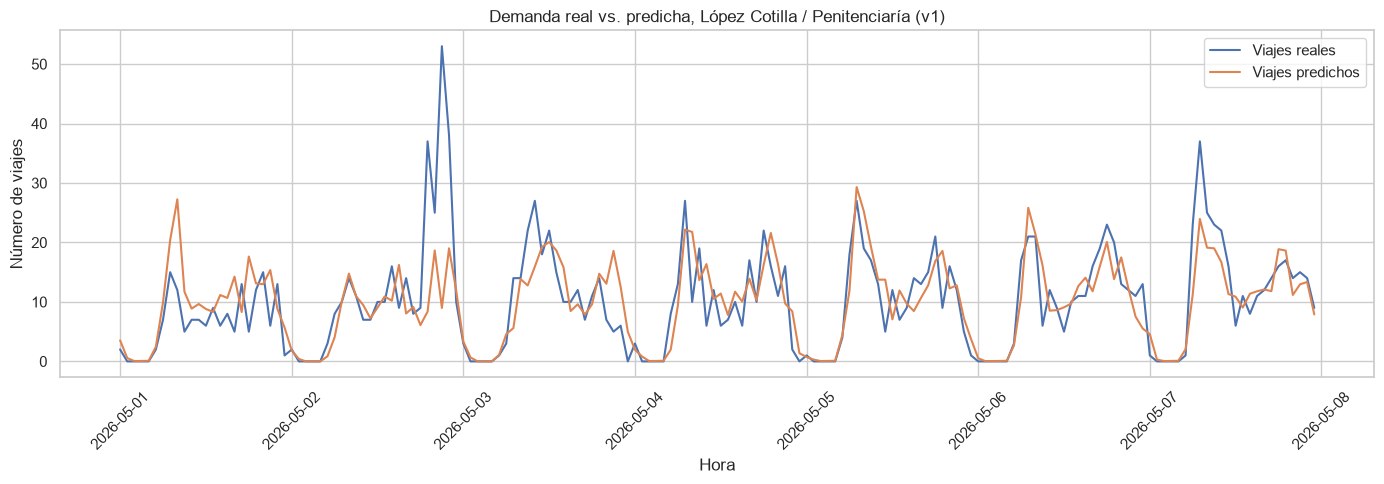

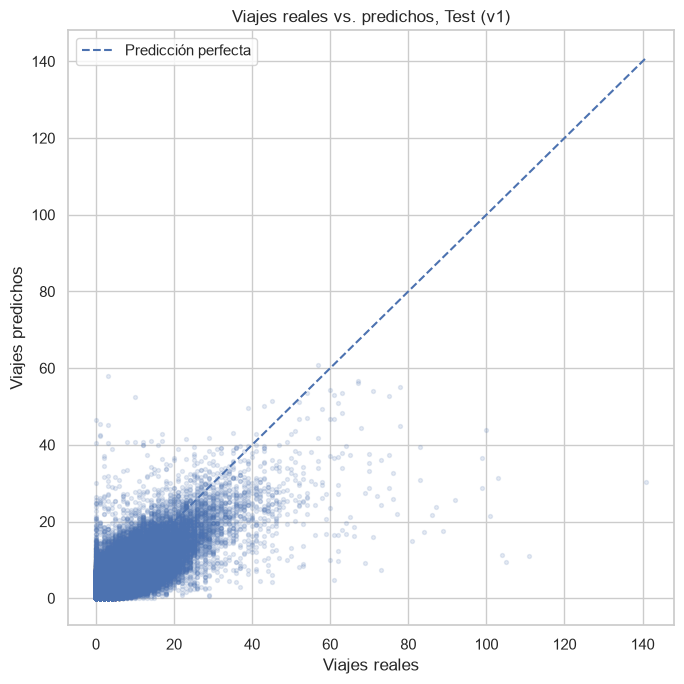

/var/folders/wf/zp59pk9n53g840vgbj1n2ghh0000gn/T/ipykernel_55243/799293355.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  g = g[g["target_hour"] < g["target_hour"].min() + pd.Timedelta(days=7)]
/Users/marthag/Documents/MNA/MLOps/pruebasEquipo20/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. 

🏃 View run P1_v2_rolling_mean at: http://127.0.0.1:8080/#/experiments/2/runs/71b69cdc082d4d6ba96a465d89d114c3
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/2


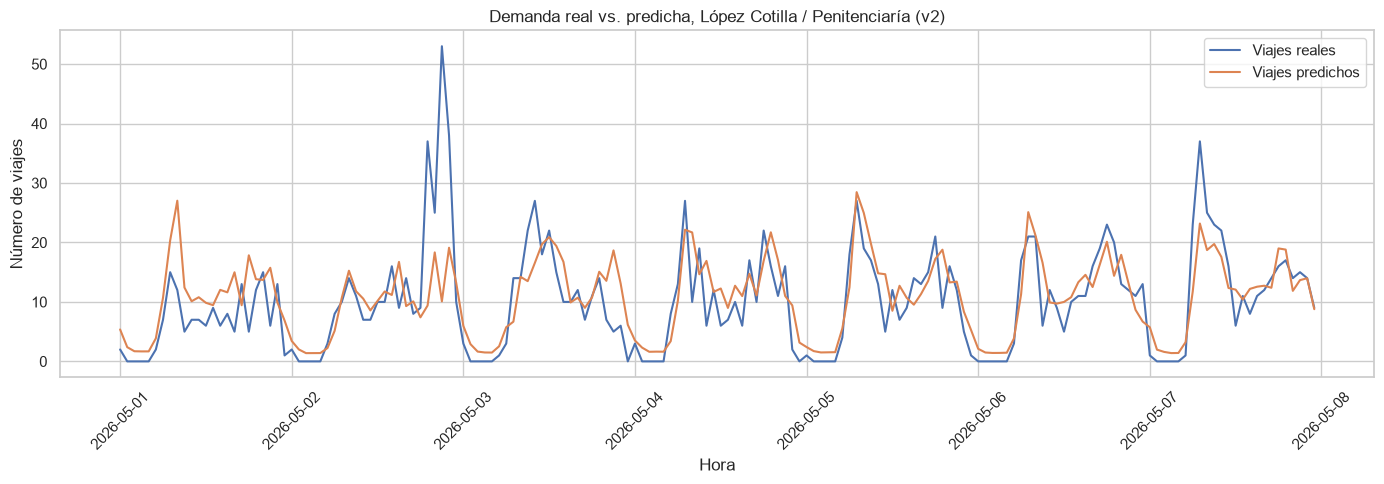

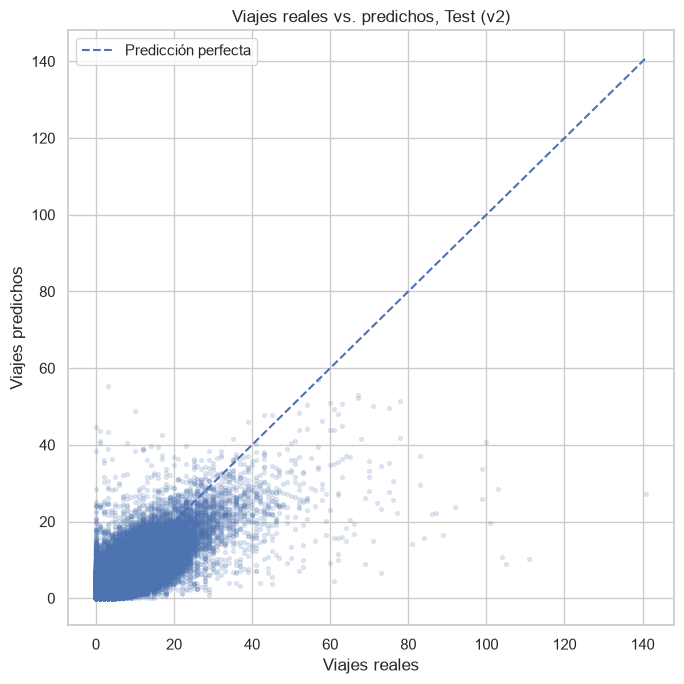

In [1296]:
modelo_v1, tabla_v1, est_v1, run_v1 = correr_modelo("P1_v1_linear", features_final, "v1")
modelo_v2, tabla_v2, est_v2, run_v2 = correr_modelo("P1_v2_rolling_mean", features_v2, "v2")

for n, t in [("v1_lineal", tabla_v1), ("v2_lineal_rolling", tabla_v2)]:
    resumen.append({"modelo": n, **t.set_index("conjunto").loc["Test"].to_dict()})

In [1297]:
comparacion = (
    pd.DataFrame(resumen)
    .drop_duplicates(subset="modelo", keep="last")
    .set_index("modelo")
)
comparacion

,MAE,RMSE,WAPE,Sesgo
modelo,,,,
naive_persistencia,1.049829,1.997705,0.838597,-0.000336
naive_lag_24h,1.035149,2.138918,0.826871,-0.004947
naive_lag_168h,0.964459,1.948918,0.770404,-0.026451
naive_promedio_24h_168h,0.886978,1.728642,0.708513,-0.015699
v1_lineal,0.865289,1.558243,0.691188,0.008708
v2_lineal_rolling,0.852627,1.545073,0.681074,0.003638


Las reglas ingenuas ofrecen la referencia. Persistencia y lag_24h obtienen un WAPE de 0.84 y 0.83 en test, lag_168h 0.77, y el promedio de lag_24h y lag_168h 0.709, el mejor ingenuo. La regresión lineal con lags y calendario (v1) obtiene 0.691 y la versión con medias móviles (v2) 0.681, es decir, ~2.4% y ~3.9%, siendo una reducción relativa del WAPE, y ~10% menos RMSE. La ventaja sobre el promedio ingenuo es modesta; el aporte del modelo está sobre todo en reducir errores grandes. La comparación entre v1 y v2 es consistente en validación (0.670 vs 0.663).

El sesgo global es casi cero en todos los modelos, pero eso no dice nada sobre el error hora a hora ni por estación: los errores positivos y negativos se compensan. Por eso la comparación se basa en WAPE, MAE y RMSE.

A. Estaciones con mayor error absoluto acumulado

In [1298]:
est_v2.sort_values("error_abs_total", ascending=False).head(10)

,origen_id,horas_evaluadas,viajes_reales_total,viajes_predichos_total,MAE,RMSE,WAPE,Sesgo,nombre_estacion,error_abs_total
47,51,3672,48228.0,47474.566272,4.741294,6.926763,0.360994,-0.205183,(GDL-049) Lopez Cotilla / Penitenciaría,17410.032664
174,194,3672,20077.0,20121.806065,3.583797,8.084113,0.655462,0.012202,(GDL-127) Av. Vallarta / Av. de Los Arcos,13159.704321
246,271,3671,29546.0,29011.937636,3.087238,4.261780,0.383580,-0.145481,(GDL-198) Av. Alcalde / C. Hospital,11333.250233
31,35,3671,24817.0,24184.260647,2.895346,4.702243,0.428288,-0.172362,(GDL-033) Av. Hidalgo / C. Pedro Loza,10628.815693
46,50,3672,20411.0,20101.193093,2.850564,5.344539,0.512825,-0.084370,(GDL-048) C. Constancio Hernández/ Av. Juaréz,10467.269565
8,11,3672,26349.0,26046.601674,2.795329,3.873911,0.389557,-0.082352,(GDL-009) Calz. Federalismo/ C. J. Angulo,10264.449882
50,54,3671,20269.0,19828.501087,2.587614,4.482176,0.468653,-0.119994,(GDL-052) Av. Juarez /16 de Septiembre,9499.131364
34,38,3672,17939.0,17745.182297,2.141625,2.987502,0.438377,-0.052783,(GDL-036) C. Marcos Castellanos/ C. Morelos,7864.047685
48,52,3671,16335.0,16223.304695,2.084871,3.308646,0.468538,-0.030426,(GDL-050) C.Pedro Moreno /Federalismo,7653.562803
71,75,3671,15586.0,15312.757034,2.015396,2.895571,0.474690,-0.074433,(GDL-073) Av. La Paz / Av. Federalismo,7398.517068


B. Estaciones con mayor WAPE

In [1299]:
est_v2[est_v2["viajes_reales_total"] >= 500].sort_values(
    "WAPE", ascending=False
).head(10)

,origen_id,horas_evaluadas,viajes_reales_total,viajes_predichos_total,MAE,RMSE,WAPE,Sesgo,nombre_estacion,error_abs_total
134,153,3666,607.0,812.928108,0.295106,0.512198,1.782305,0.056172,(TLQ-012) C. Paseo Don Bosco / C. Tonalá,1081.859215
348,380,3668,534.0,745.560786,0.259441,0.445081,1.782077,0.057677,(TLQ-013)Zalatitan/Francisco Silva Romero,951.628916
287,318,3671,678.0,889.025872,0.303602,0.508217,1.643837,0.057485,(GDL-222) C. Aldama / C. Dr. Leonardo Oliva,1114.521619
368,401,3667,635.0,847.892010,0.283939,0.496312,1.639693,0.058056,(ZPN-079) Av. Coyoacan / C. Chimalpopoca,1041.205001
346,378,3669,723.0,912.942409,0.319675,0.519056,1.622252,0.051770,(TLQ-014) C. Hornos / C. Francisco I. Madero,1172.888425
133,152,3666,796.0,971.943269,0.347668,0.572898,1.601194,0.047993,(TLQ-011) C. Jalisco / C. Hidalgo,1274.550236
423,466,2520,530.0,654.799051,0.329915,0.546840,1.568653,0.049523,(GDL-336) G. Rivas Guillén/Álvaro Obregón,831.385960
384,422,2651,532.0,673.089672,0.313346,0.592329,1.561429,0.053221,(GDL-311) Glez Gallo / Calz.Independencia,830.680438
426,470,2382,507.0,612.123138,0.326473,0.541349,1.533841,0.044132,(GDL-348) Comonfort / C. Federico Medrano,777.657509
338,370,3669,806.0,1002.020221,0.336281,0.548688,1.530787,0.053426,(GDL-273) C. Aldama / C. Orozco Berra,1233.814655


C. Comparación v1 contra v2 por estación (nueva)

In [1300]:
cmp = (
    est_v1[["origen_id", "nombre_estacion", "viajes_reales_total", "WAPE", "Sesgo"]]
    .merge(est_v2[["origen_id", "WAPE", "Sesgo"]],
           on="origen_id", suffixes=("_v1", "_v2"))
)

print("Estaciones de mayor demanda:")
display(cmp.sort_values("viajes_reales_total", ascending=False).head(5))

print("Estaciones de menor demanda (con al menos 500 viajes reales):")
display(cmp[cmp["viajes_reales_total"] >= 500]
        .sort_values("viajes_reales_total").head(5))

# ¿el sesgo ya no depende del volumen de la estación?
cmp["sesgo_rel_v1"] = cmp["Sesgo_v1"] / (cmp["viajes_reales_total"] / 3670)
cmp["sesgo_rel_v2"] = cmp["Sesgo_v2"] / (cmp["viajes_reales_total"] / 3670)
print("Sesgo relativo mediano (v1 y v2):", #Aproximado: divide entre 3670 horas fijas
      cmp["sesgo_rel_v1"].median().round(3), cmp["sesgo_rel_v2"].median().round(3))

Estaciones de mayor demanda:


,origen_id,nombre_estacion,viajes_reales_total,WAPE_v1,Sesgo_v1,WAPE_v2,Sesgo_v2
47,51,(GDL-049) Lopez Cotilla / Penitenciaría,48228.0,0.337654,-1.340090,0.360994,-0.205183
246,271,(GDL-198) Av. Alcalde / C. Hospital,29546.0,0.359956,-0.782211,0.383580,-0.145481
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,26349.0,0.365225,-0.640908,0.389557,-0.082352
31,35,(GDL-033) Av. Hidalgo / C. Pedro Loza,24817.0,0.403930,-0.698395,0.428288,-0.172362
46,50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,20411.0,0.495089,-0.493390,0.512825,-0.084370


Estaciones de menor demanda (con al menos 500 viajes reales):


,origen_id,nombre_estacion,viajes_reales_total,WAPE_v1,Sesgo_v1,WAPE_v2,Sesgo_v2
424,467,(GDL-337) Ortiz de Domínguez/Pánfilo Pérez,500.0,1.641057,0.117795,1.407587,0.038926
408,449,(GDL-312) J.D. Covarrubias / Esteban Alatorre,507.0,1.532836,0.122974,1.352041,0.044763
426,470,(GDL-348) Comonfort / C. Federico Medrano,507.0,1.782344,0.124301,1.533841,0.044132
96,104,(ZPN-104) Av. D / C. 9,510.0,1.172445,0.089199,1.086411,0.016092
462,518,(ZPN-108) Av. Atemajac / Av. Yermo y Parra,516.0,1.116492,0.071579,1.055170,0.002892


Sesgo relativo mediano (v1 y v2): 0.075 0.013


Como muestran las tablas, no se incluyó una media histórica por estación. Los resultados por estación del baseline muestran un sesgo sistemático según el nivel de demanda (subestimación en estaciones de alta demanda y sobreestimación en las de baja), lo que indica que el nivel de cada estación es información faltante. Una media fija calculada con train requeriría almacenar una tabla de consulta, definir un criterio de arranque en frío para estaciones nuevas y se desactualizaría si la demanda cambia. En su lugar, la versión 2 usa medias móviles que dependen solo de horas pasadas.

La media móvil corrigió el sesgo sistemático por nivel de demanda: en las cinco estaciones de mayor volumen el sesgo se redujo entre 75% y 87%, y el sesgo relativo mediano pasó de 7.5% a 1.3%. Sin embargo, el WAPE de esas estaciones aumentó ligeramente (por ejemplo, Penitenciaría de 0.338 a 0.361), por lo que corregir el sesgo no redujo el error hora a hora. En estaciones de baja demanda el WAPE sigue por encima de 1: la regresión lineal minimiza el error cuadrático y predice valores cercanos a la media, mientras que con conteos casi siempre en cero un valor cercano a cero minimiza el error absoluto. Esto sugiere que la limitante es la forma del modelo y no solo la falta de variables.

#### Conclusiones

La regresión lineal supera de forma modesta al mejor ingenuo (WAPE 0.681 contra 0.709) y con claridad a persistencia y lag_24h (0.68 contra 0.84 y 0.83). Dado que la demanda es un conteo con 54% de ceros, modelos con pérdida Poisson o de árboles con boosting son los siguientes pasos naturales. Las ventanas de las medias móviles (3 y 168 h) se fijaron a priori y no se optimizaron.

Cada estación necesita 167 horas de historial para generar su primera predicción, por lo que la evaluación no incluye la primera semana de estaciones nuevas. Una estrategia para ese periodo queda como trabajo futuro.